### 0. Defining constants and functions

In [1]:
using LinearAlgebra
using Plots
using Plots.Measures
using LambertW
using Distributions
using Statistics
using QuadGK

# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 1.0      #(in m^2/s^2)

1.0

In [2]:
# Function
f(h, l, x) = -log(l/L) * ((h - c1)^2 / (2c2) - h) + 0.5 * (x/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, x) selon h
fprime(h, l, x) = -log(l/L) * ((h - c1)/c2 - 1 + (x/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, x) selon h
fsecond(h, l, x) = -log(l/L) * (1/c2 - 2 * (x/σ)^2 * log(l/L) * (l/L)^(-2h))


fsecond (generic function with 1 method)

### 1. Non-normalized PDF, computed with QuadGK

##### a. P_{δ_ℓu} and log(P_{δ_ℓu})

In [3]:
function safe_integrand_pdf(h, l, x)
    val = exp(-f(h,l,x))
    return isfinite(val) ? val : 0.0
end

function compute_P_δlu_of_x(l, x)
    prefactor = (1 / (2π*σ)) * sqrt(-log(l/L) / c2)

    integral, err = quadgk(
        h -> safe_integrand_pdf(h,l,x),
        -Inf, Inf;
    )

    return prefactor * integral
end

compute_P_δlu_of_x (generic function with 1 method)

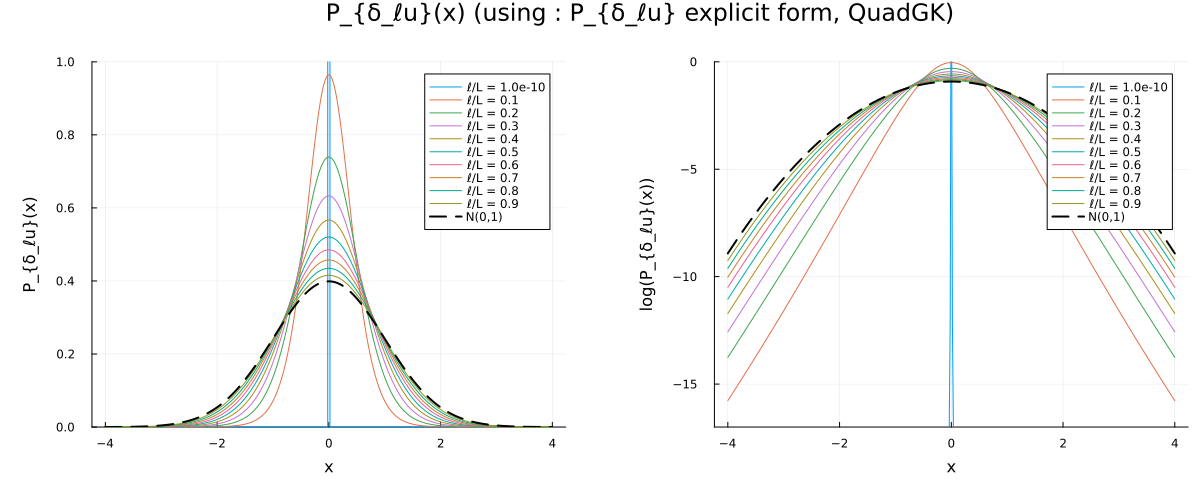

In [4]:
# 1. Setup l and x values
l_values = 1e-10*L:0.1*L:L
x_values = -4:0.02:4

# 2. Initialize plots with explicit scales
p1 = plot(xlabel = "x", ylabel = "P_{δ_ℓu}(x)", ylims=(0, 1), lw = 2, left_margin = 10mm, bottom_margin = 10mm)
p2 = plot(xlabel = "x", ylabel = "log(P_{δ_ℓu}(x))", ylims=(-17, 0), lw = 2, left_margin = 20mm, bottom_margin = 10mm) # Note the :log scale here

# 3. Reference Gaussian (Computed once)
gauss_pdf = pdf.(Normal(0, 1), x_values)

# 4. Plot loop
for l in l_values
    P_values = compute_P_δlu_of_x.(Ref(l), x_values)
    label = "ℓ/L = $(round(l/L, sigdigits=2))"

    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, log.(P_values), label = label) # Plotting P_values, the axis scale handles the log
end

# 5. Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, log.(gauss_pdf), label="N(0,1)", lw=2, ls=:dash, color=:black)

# 6. Final Layout
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "P_{δ_ℓu}(x) (using : P_{δ_ℓu} explicit form, QuadGK)", plot_titlevspan=0.1)

##### b. Entropy

In [5]:
function compute_entropy_for_l(p_function, l, h_star=nothing)
    # Define the integrand logic based on whether h_star (the function) is provided
    if isnothing(h_star)
        integrand = x -> begin
            p = p_function(l, x)
            val = p > 0 ? -p * log(p) : 0.0
            return isfinite(val) ? val : 0.0
        end
    else
        integrand = x -> begin
            # Here, h_star is called as a function inside the call to p_function
            p = p_function(l, x, h_star)
            val = p > 0 ? -p * log(p) : 0.0
            return isfinite(val) ? val : 0.0
        end
    end

    # Numerical integration
    entropy, err = quadgk(integrand, -Inf, Inf)
    
    return entropy
end

compute_entropy_for_l (generic function with 2 methods)

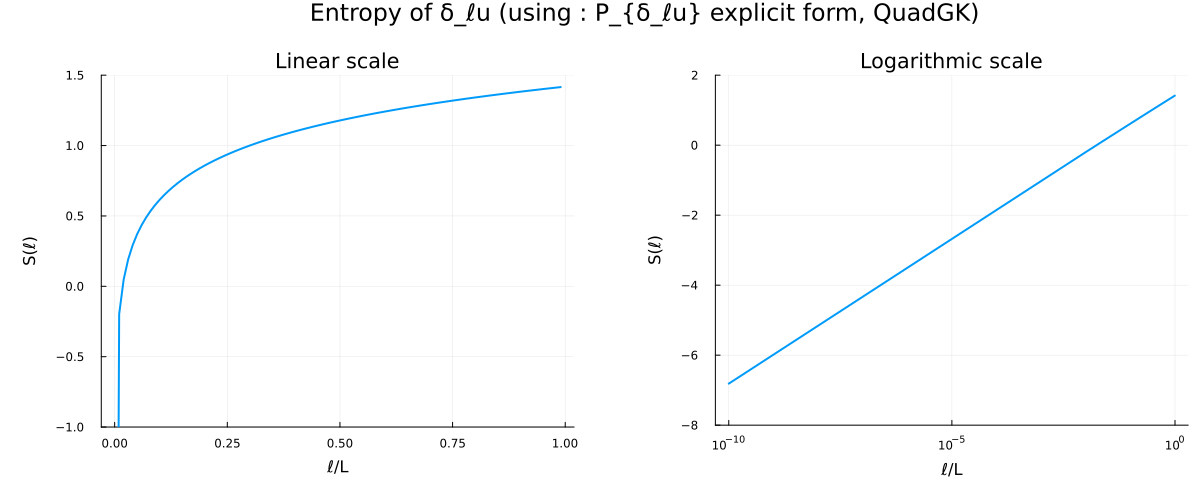

In [6]:
# Define l values
l_values = 1e-10*L:0.01*L:L
S_values = [compute_entropy_for_l(compute_P_δlu_of_x,l) for l in l_values]

# Create the plot for S(l)
p1 = plot(l_values./L, S_values,
          title = "Linear scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims = (-1, 1.5),
          lw = 2,
          legend = false,
          left_margin = 10mm,
          bottom_margin = 10mm)

p2 = plot(l_values./L, S_values,
          title = "Logarithmic scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims = (-8, 2),
          xscale = :log10,
          lw = 2,
          legend = false,
          left_margin = 20mm,
          bottom_margin = 10mm)

# Plot
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "Entropy of δ_ℓu (using : P_{δ_ℓu} explicit form, QuadGK)", plot_titlevspan=0.1)

### 2. Non-normalized PDF, computed using Laplace approximation with h*=c_1

##### a. P_{δ_ℓu} and log(P_{δ_ℓu})

In [7]:
# Value of h_star
h_star(l, x) = c1

h_star (generic function with 1 method)

In [8]:
function compute_P_δlu_of_x_Laplace(l, x, h_star, tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_x_Laplace (generic function with 3 methods)

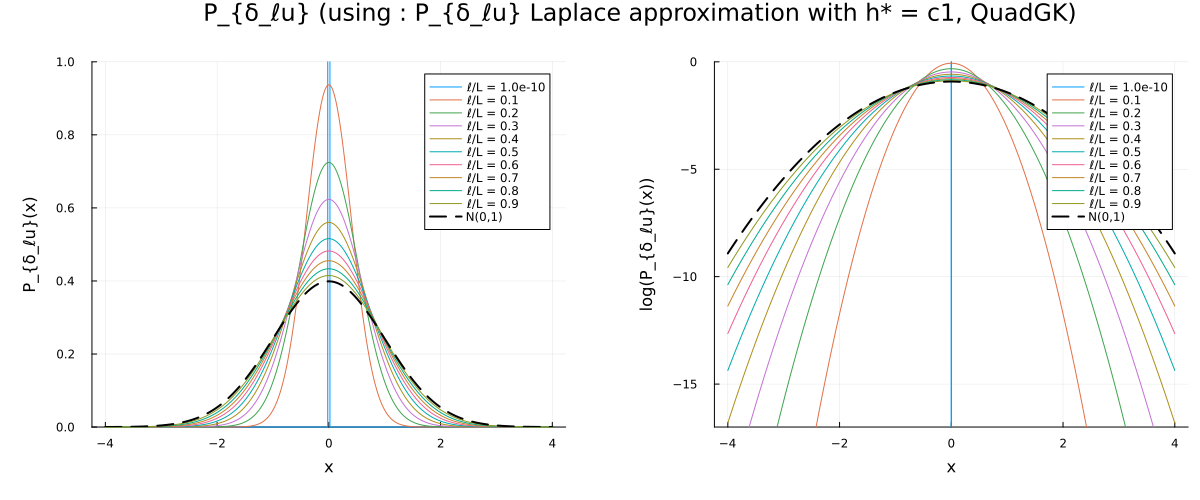

In [9]:
# 1. Setup l and x values
l_values = 1e-10*L:0.1*L:L
x_values = -4:0.02:4

# 2. Initialize plots with explicit scales
p1 = plot(xlabel = "x", ylabel = "P_{δ_ℓu}(x)", ylims=(0, 1), lw = 2, left_margin = 10mm, bottom_margin = 10mm)
p2 = plot(xlabel = "x", ylabel = "log(P_{δ_ℓu}(x))", ylims=(-17, 0), lw = 2, left_margin = 20mm, bottom_margin = 10mm)
# 3. Reference Gaussian (Computed once)
gauss_pdf = pdf.(Normal(0, 1), x_values)

# 4. Plot loop
for l in l_values
    
    P_values = compute_P_δlu_of_x_Laplace.(Ref(l), x_values, Ref(h_star))
    
    label = "ℓ/L = $(round(l/L, sigdigits=2))"
    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, log.(P_values), label = label) # Plotting P_values, the axis scale handles the log
end

# 5. Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, log.(gauss_pdf), label="N(0,1)", lw=2, ls=:dash, color=:black)

# 6. Final Layout
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "P_{δ_ℓu} (using : P_{δ_ℓu} Laplace approximation with h* = c1, QuadGK)", plot_titlevspan=0.1)

##### b. Entropy

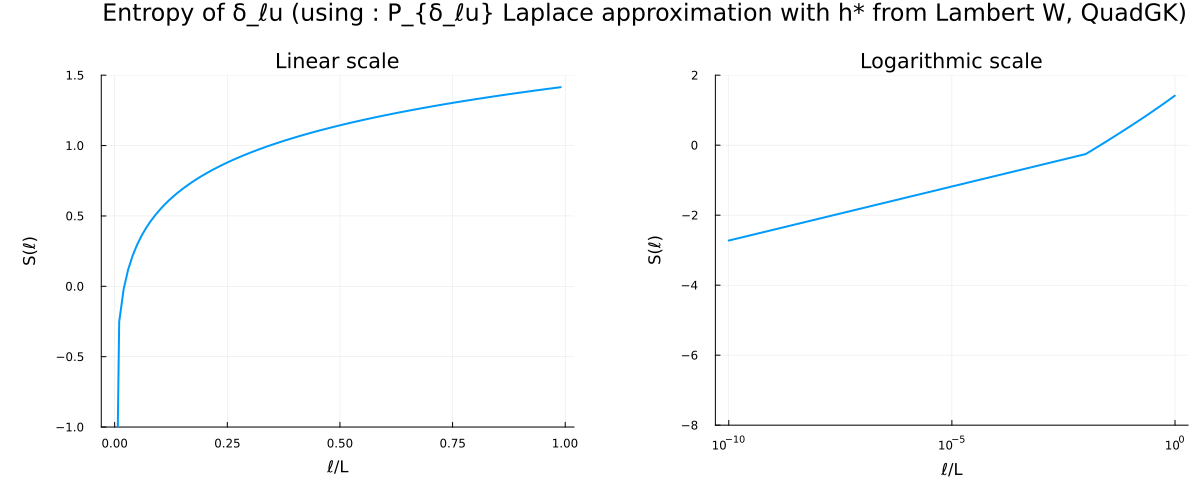

In [10]:
# Define l values
l_values = 1e-10*L:0.01*L:L
S_values = [compute_entropy_for_l(compute_P_δlu_of_x_Laplace, l, h_star) for l in l_values]

# Create the plot for S(l)
p1 = plot(l_values./L, S_values,
          title = "Linear scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims=(-1, 1.5),
          lw = 2,
          legend = false,
          left_margin = 10mm,
          bottom_margin = 10mm)

p2 = plot(l_values./L, S_values,
          title = "Logarithmic scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims=(-8, 2),
          xscale = :log10,
          lw = 2,
          legend = false,
          left_margin = 20mm,
          bottom_margin = 10mm)

# Plot
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "Entropy of δ_ℓu (using : P_{δ_ℓu} Laplace approximation with h* from Lambert W, QuadGK)", plot_titlevspan=0.1)

### 3. Non-normalized PDF, computed using Laplace approximation with h* from Lambert W

##### a. P_{δ_ℓu} and log(P_{δ_ℓu})

In [11]:
# Value of h_star
h_star(l, x) = (c1 + c2) - lambertw(2 * c2 * abs(log(l / L)) * ((x / σ)^2) * exp(2 * (c1 + c2) * abs(log(l / L)))) / (2 * abs(log(l / L)))

h_star (generic function with 1 method)

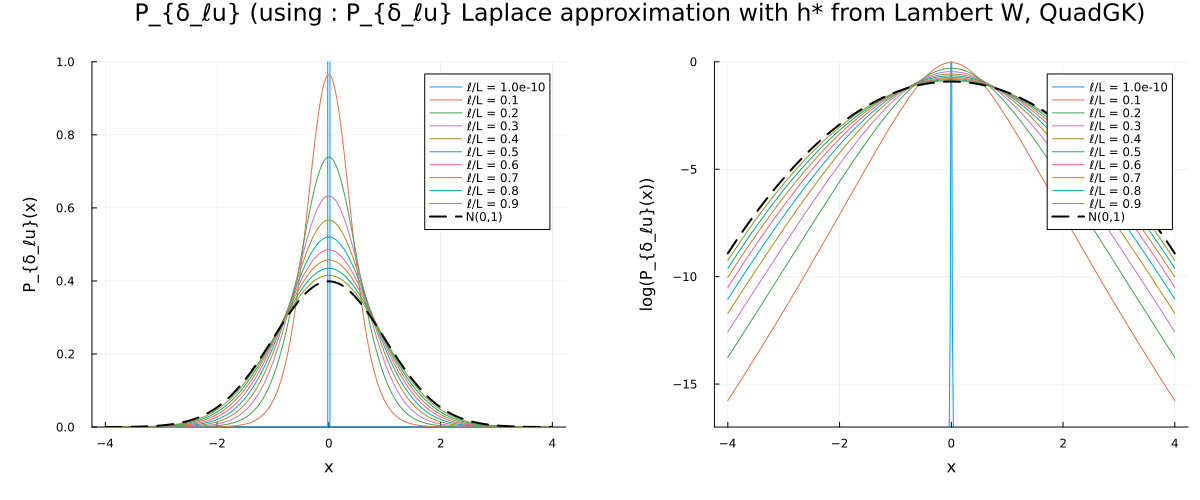

In [12]:
# 1. Setup l and x values
l_values = 1e-10*L:0.1*L:L
x_values = -4:0.02:4

# 2. Initialize plots with explicit scales
p1 = plot(xlabel = "x", ylabel = "P_{δ_ℓu}(x)", ylims=(0, 1), lw = 2, left_margin = 10mm, bottom_margin = 10mm)
p2 = plot(xlabel = "x", ylabel = "log(P_{δ_ℓu}(x))", ylims=(-17, 0), lw = 2, left_margin = 20mm, bottom_margin = 10mm)
# 3. Reference Gaussian (Computed once)
gauss_pdf = pdf.(Normal(0, 1), x_values)

# 4. Plot loop
for l in l_values
    
    P_values = compute_P_δlu_of_x_Laplace.(Ref(l), x_values, Ref(h_star))
    
    label = "ℓ/L = $(round(l/L, sigdigits=2))"
    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, log.(P_values), label = label) # Plotting P_values, the axis scale handles the log
end

# 5. Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, log.(gauss_pdf), label="N(0,1)", lw=2, ls=:dash, color=:black)

# 6. Final Layout
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "P_{δ_ℓu} (using : P_{δ_ℓu} Laplace approximation with h* from Lambert W, QuadGK)", plot_titlevspan=0.1)

##### b. Entropy

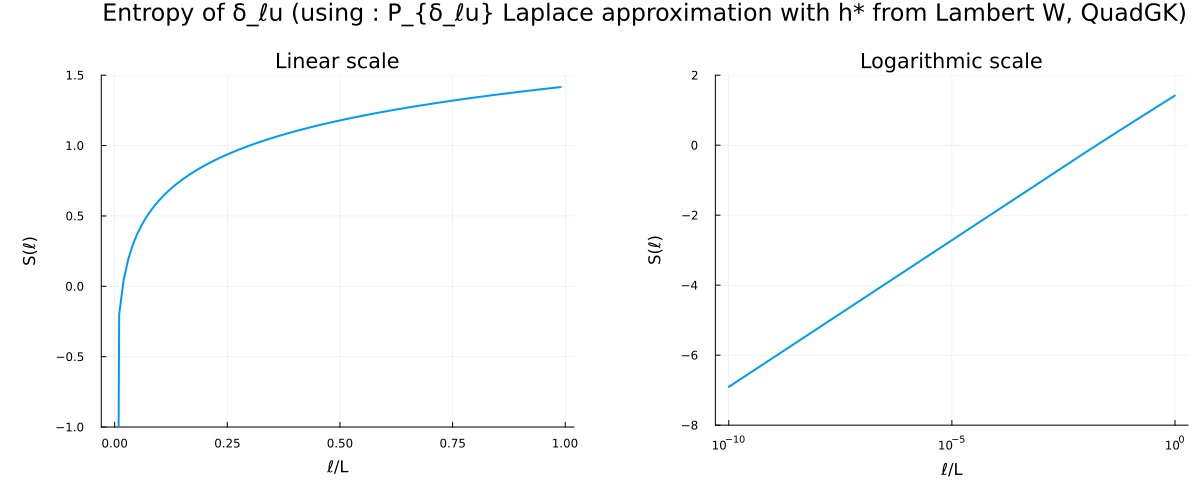

In [139]:
# Define l values
l_values = 1e-10*L:0.01*L:L
S_values = [compute_entropy_for_l(compute_P_δlu_of_x_Laplace, l, h_star) for l in l_values]

# Create the plot for S(l)
p1 = plot(l_values./L, S_values,
          title = "Linear scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims=(-1, 1.5),
          lw = 2,
          legend = false,
          left_margin = 10mm, 
          bottom_margin = 10mm)

p2 = plot(l_values./L, S_values,
          title = "Logarithmic scale",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          ylims=(-8, 2),
          xscale = :log10,
          lw = 2,
          legend = false,
          left_margin = 20mm,
          bottom_margin = 10mm)

# Plot
plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "Entropy of δ_ℓu (using : P_{δ_ℓu} Laplace approximation with h* from Lambert W, QuadGK)", plot_titlevspan=0.1)

### 4. Second order structure, flatness, skewness

In [132]:
# Defining structure functions

function S2(l)
    integral, _ = quadgk(
        x -> x^2 * compute_P_δlu_of_x(l, x),
        -Inf, Inf;
    )

    return integral
end

function S3(l)
    integral, _ = quadgk(
        x -> x^3 * compute_P_δlu_of_x(l, x),
        -Inf, Inf,
        atol=1e-9
    )

    return integral
end

function S4(l)
    integral, _ = quadgk(
        x -> x^4 * compute_P_δlu_of_x(l, x),
        -Inf, Inf;
    )

    return integral
end

S4 (generic function with 1 method)

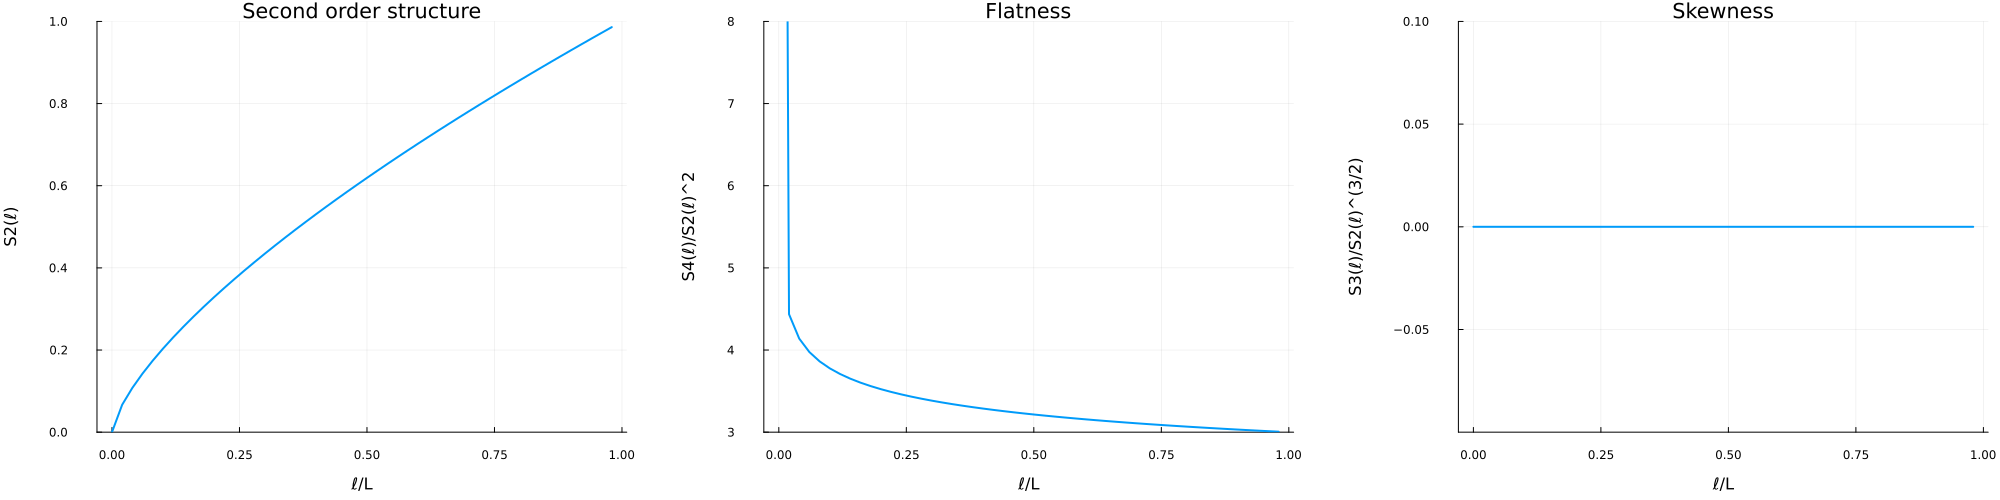

In [133]:
# Define l values
l_values = 1e-10*L:0.02*L:L

# Compute S2, Flatness, and Skewness for each l
S2_values = [S2(l) for l in l_values]
Flatness_values = [S4(l)/(S2(l)^2) for l in l_values]
Skewness_values = [S3(l)/(S2(l)^(3/2)) for l in l_values]

# Create the plot
p1 = plot(l_values./L, S2_values,
          title = "Second order structure",
          xlabel = "ℓ/L",
          ylabel = "S2(ℓ)",
          ylims=(0, 1),
          lw = 2,
          legend = false,
          left_margin = 10mm,
          bottom_margin = 10mm)

p2 = plot(l_values./L, Flatness_values,
          title = "Flatness",
          xlabel = "ℓ/L",
          ylabel = "S4(ℓ)/S2(ℓ)^2",
          ylims=(3, 8),
          lw = 2,
          legend = false,
          left_margin = 20mm,
          bottom_margin = 10mm)

p3 = plot(l_values./L, Skewness_values,
          title = "Skewness",
          xlabel = "ℓ/L",
          ylabel = "S3(ℓ)/S2(ℓ)^(3/2)",
          ylims=(-0.1, 0.1),
          lw = 2,
          legend = false,
          left_margin = 20mm,
          bottom_margin = 10mm)

# Plot
plot(p1, p2, p3, layout = (1, 3), size = (2000, 500))